## Name : Saloni Salem

## SI Project

## Roll No : B22-18

#### Job Description Classification Using Web Scraping, Statistical Analysis and Machine Learning

In [2]:
%pip install lxml html5lib beautifulsoup4 -q

import re
import requests
from bs4 import BeautifulSoup

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import lxml
import html5lib

np.random.seed(42)

Note: you may need to restart the kernel to use updated packages.


# Part 1 — Web Scraping
The page below describes what a job description is. It is scraped to build a small keyword vocabulary that is later compared with the dataset.

In [3]:
# Web scraping: a public page that explains what a job description contains
url = "https://en.wikipedia.org/wiki/Job_description"

headers = {"User-Agent": "Mozilla/5.0 (educational SI project)"}

try:
    response = requests.get(url, headers=headers, timeout=15)
    print("Status Code:", response.status_code)
except requests.exceptions.RequestException as e:
    response = None
    print("Could not reach the page:", e)

Status Code: 200


In [4]:
if response is not None and response.ok:
    soup = BeautifulSoup(response.text, "html.parser")
    print(soup.title.text)
else:
    soup = None
    print("Skipping: page was not downloaded.")

Job description - Wikipedia


In [5]:
if soup is not None:
    paragraphs = [p.get_text(" ", strip=True) for p in soup.find_all("p")]
    page_text = " ".join(paragraphs)
    print(page_text[:3000])

 A job description or JD is a written narrative that describes the general tasks, or other related duties, and responsibilities of a position. It may specify the functionary to whom the position reports, specifications such as the qualifications or skills needed by the person in the job, information about the equipment, tools and work aids used, working conditions, physical demands, and a salary range. Job descriptions are usually narrative, [ 1 ] but some may comprise a simple list of competencies; for instance, strategic human resource planning methodologies may be used to develop a competency architecture for an organization, from which job descriptions are built as a shortlist of competencies. [ 2 ] [ not specific enough to verify ] According to Torrington, a job description is usually developed by conducting a job analysis , which includes examining the tasks and sequences of tasks necessary to perform the job. The analysis considers the areas of knowledge , skills and abilities n

In [6]:
if soup is not None:
    text = soup.get_text(" ", strip=True)

    keywords = [
        "responsibilities",
        "qualifications",
        "skills",
        "experience",
        "salary"
    ]

    for keyword in keywords:
        if keyword.lower() in text.lower():
            print("Found:", keyword)

Found: responsibilities
Found: qualifications
Found: skills
Found: experience
Found: salary


In [7]:
# Most frequent meaningful words on the scraped page
if soup is not None:
    words = re.findall(r"[a-z]{4,}", page_text.lower())
    stop = {"that", "this", "with", "from", "have", "which", "their", "also", "such", "been",
            "were", "they", "than", "these", "other", "into", "more", "will", "when", "used"}
    freq = pd.Series([w for w in words if w not in stop]).value_counts().head(15)
    print(freq)

description         21
descriptions        11
information          8
management           8
analysis             7
requirements         6
manipulation         6
organizations        6
tasks                5
responsibilities     5
qualifications       5
skills               5
organization         5
perform              5
knowledge            5
Name: count, dtype: int64


# Part 2 — Dataset and Data Loading
The notebook first tries to read a real job-description CSV (columns: `job_description`, `category`). If the file is not found, it builds a **synthetic labelled dataset** so the whole notebook still runs end to end.

To use a real dataset (e.g. a Kaggle "Job Description Classification / Job Postings" CSV), place it next to this notebook as `job_descriptions.csv` and rename its columns to `job_description` and `category`.

In [8]:
metadata = {
    "Dataset Name": "Job Description Classification",
    "Source": "Local CSV (job_descriptions.csv) or built-in synthetic generator",
    "Input": "Free-text job description",
    "Target": "Job category (multi-class)",
    "Task": "Text classification",
    "Domain": "Human Resources / Recruitment"
}

metadata_df = pd.DataFrame(
    metadata.items(),
    columns=["Property", "Value"]
)

metadata_df

,Property,Value
0,Dataset Name,Job Description Classification
1,Source,Local CSV (job_descriptions.csv) or built-in s...
2,Input,Free-text job description
3,Target,Job category (multi-class)
4,Task,Text classification
5,Domain,Human Resources / Recruitment


In [9]:
def make_synthetic_jobs(n_per_class=250, seed=42):
    rng = np.random.default_rng(seed)

    profiles = {
        "Data Science": {
            "titles": ["Data Scientist", "Machine Learning Engineer", "Data Analyst", "AI Researcher"],
            "skills": ["python", "machine learning", "statistics", "sql", "pandas", "tensorflow",
                       "data visualization", "deep learning", "nlp", "scikit-learn"],
            "tasks": ["build predictive models", "analyze large datasets", "design experiments",
                      "deploy machine learning pipelines", "create dashboards for stakeholders"],
            "exp": (1, 8), "sal": (7, 30)},
        "Software Development": {
            "titles": ["Software Engineer", "Backend Developer", "Full Stack Developer", "Java Developer"],
            "skills": ["java", "python", "javascript", "react", "microservices", "git", "rest api",
                       "docker", "data structures", "agile"],
            "tasks": ["develop scalable applications", "write clean and tested code",
                      "review pull requests", "maintain backend services", "fix production bugs"],
            "exp": (1, 10), "sal": (6, 28)},
        "Marketing": {
            "titles": ["Marketing Manager", "Digital Marketer", "SEO Specialist", "Brand Executive"],
            "skills": ["seo", "content strategy", "social media", "google analytics", "branding",
                       "email campaigns", "copywriting", "market research", "advertising"],
            "tasks": ["plan marketing campaigns", "grow brand awareness", "manage social media channels",
                      "analyze campaign performance", "coordinate with creative teams"],
            "exp": (1, 9), "sal": (4, 20)},
        "Human Resources": {
            "titles": ["HR Executive", "Talent Acquisition Specialist", "HR Business Partner", "Recruiter"],
            "skills": ["recruitment", "onboarding", "employee engagement", "payroll", "labour law",
                       "performance management", "communication", "hr policies"],
            "tasks": ["source and screen candidates", "conduct interviews", "manage employee records",
                      "run onboarding programs", "resolve employee grievances"],
            "exp": (1, 9), "sal": (3, 18)},
        "Finance": {
            "titles": ["Financial Analyst", "Accountant", "Audit Associate", "Investment Analyst"],
            "skills": ["financial modelling", "excel", "accounting", "budgeting", "taxation",
                       "auditing", "forecasting", "tally", "risk analysis"],
            "tasks": ["prepare financial statements", "perform variance analysis", "support audits",
                      "manage budgets and forecasts", "reconcile accounts"],
            "exp": (1, 10), "sal": (4, 22)},
        "Sales": {
            "titles": ["Sales Executive", "Business Development Manager", "Account Manager", "Inside Sales Representative"],
            "skills": ["lead generation", "negotiation", "crm", "client relationship", "cold calling",
                       "presentation skills", "target achievement", "b2b sales"],
            "tasks": ["generate new business leads", "meet monthly sales targets", "maintain client relationships",
                      "prepare proposals and quotations", "close deals with customers"],
            "exp": (0, 9), "sal": (3, 20)},
        "Design": {
            "titles": ["UI/UX Designer", "Graphic Designer", "Product Designer", "Visual Designer"],
            "skills": ["figma", "adobe photoshop", "wireframing", "prototyping", "typography",
                       "user research", "illustrator", "design systems"],
            "tasks": ["design intuitive user interfaces", "create wireframes and prototypes",
                      "conduct user research", "maintain the design system", "collaborate with developers"],
            "exp": (1, 8), "sal": (4, 22)},
    }

    openers = ["We are looking for a", "Our company is hiring a", "Join our team as a",
               "An exciting opportunity for a", "We are seeking an experienced"]
    fillers = ["Strong communication skills are required.", "You will work in a collaborative team environment.",
               "Excellent problem solving ability is a plus.", "Ability to meet deadlines is essential.",
               "This is a full time position with growth opportunities.", "Good team player with a positive attitude."]

    rows = []
    for category, p in profiles.items():
        for _ in range(n_per_class):
            # half of the postings use a generic title, so the title alone does not reveal the category
            title = rng.choice(p["titles"]) if rng.random() < 0.5 else rng.choice(
                ["Associate", "Executive", "Specialist", "Team Member", "Analyst", "Manager"])
            skills = rng.choice(p["skills"], size=rng.integers(3, 6), replace=False)
            tasks = rng.choice(p["tasks"], size=rng.integers(2, 4), replace=False)
            exp = int(rng.integers(p["exp"][0], p["exp"][1] + 1))
            salary = round(float(rng.uniform(*p["sal"])) + exp * 0.8, 1)

            # a little cross-category noise so the problem is not trivially separable
            # (1-3 skills borrowed from other categories, and 25% of postings keep only one own skill)
            if rng.random() < 0.25:
                skills = skills[:1]
                tasks = tasks[:1]
            # 30% of postings borrow one responsibility from another category
            if rng.random() < 0.30:
                other_c = rng.choice([c for c in profiles.keys() if c != category])
                tasks = np.append(tasks[:-1], rng.choice(profiles[other_c]["tasks"]))
            noise_words = ""
            if rng.random() < 0.85:
                borrowed = []
                for _ in range(int(rng.integers(1, 4))):
                    other = rng.choice([c for c in profiles.keys() if c != category])
                    borrowed.append(str(rng.choice(profiles[other]["skills"])))
                noise_words = " Familiarity with " + ", ".join(borrowed) + " is helpful."

            desc = (f"{rng.choice(openers)} {title} with {exp}+ years of experience. "
                    f"Responsibilities: {', '.join(tasks)}. "
                    f"Required skills: {', '.join(skills)}. "
                    f"{rng.choice(fillers)}{noise_words}")
            rows.append({"job_description": desc, "category": category,
                         "experience_years": exp, "salary_lpa": salary})

    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)

In [10]:
try:
    df = pd.read_csv("job_descriptions.csv")
    df = df[["job_description", "category"]].copy() if "experience_years" not in df.columns else df
    print("Loaded local file job_descriptions.csv")
    using_synthetic = False
except Exception as e:
    print("Local file not found:", e)
    print("Using the built-in synthetic dataset instead.")
    df = make_synthetic_jobs()
    using_synthetic = True

df.head()

Local file not found: [Errno 2] No such file or directory: 'job_descriptions.csv'
Using the built-in synthetic dataset instead.


,job_description,category,experience_years,salary_lpa
0,We are looking for a Analyst with 5+ years of ...,Finance,5,17.1
1,Join our team as a Talent Acquisition Speciali...,Human Resources,4,11.1
2,Our company is hiring a Java Developer with 7+...,Software Development,7,31.6
3,We are looking for a HR Business Partner with ...,Human Resources,3,18.5
4,Join our team as a Team Member with 1+ years o...,Design,1,11.3


In [11]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1750
Columns: 4


In [12]:
df.head()

,job_description,category,experience_years,salary_lpa
0,We are looking for a Analyst with 5+ years of ...,Finance,5,17.1
1,Join our team as a Talent Acquisition Speciali...,Human Resources,4,11.1
2,Our company is hiring a Java Developer with 7+...,Software Development,7,31.6
3,We are looking for a HR Business Partner with ...,Human Resources,3,18.5
4,Join our team as a Team Member with 1+ years o...,Design,1,11.3


In [13]:
df.tail()

,job_description,category,experience_years,salary_lpa
1745,We are seeking an experienced Executive with 1...,Finance,10,25.7
1746,We are seeking an experienced Specialist with ...,Sales,9,25.5
1747,Join our team as a Manager with 4+ years of ex...,Human Resources,4,11.2
1748,An exciting opportunity for a Team Member with...,Sales,0,17.7
1749,An exciting opportunity for a Team Member with...,Finance,1,13.8


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1750 entries, 0 to 1749
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   job_description   1750 non-null   str    
 1   category          1750 non-null   str    
 2   experience_years  1750 non-null   int64  
 3   salary_lpa        1750 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 574.5 KB


In [15]:
df.describe(include="all")

,job_description,category,experience_years,salary_lpa
count,1750,1750,1750.000000,1750.000000
unique,1750,7,NaN,NaN
top,We are looking for a Analyst with 5+ years of ...,Finance,NaN,NaN
freq,1,250,NaN,NaN
mean,NaN,NaN,4.966857,17.647829
std,NaN,NaN,2.673599,6.486622
min,NaN,NaN,0.000000,3.100000
25%,NaN,NaN,3.000000,12.700000
50%,NaN,NaN,5.000000,17.350000
75%,NaN,NaN,7.000000,22.075000


In [16]:
df.dtypes

job_description         str
category                str
experience_years      int64
salary_lpa          float64
dtype: object

# Part 3 — Data Cleaning

In [17]:
missing = df.isnull().sum()

print(missing)

job_description     0
category            0
experience_years    0
salary_lpa          0
dtype: int64


In [18]:
# Check for duplicate rows and remove them
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", len(df))

Duplicate rows: 0
Rows after removing duplicates: 1750


In [19]:
# Drop rows without text or label, since they cannot be used for classification
df = df.dropna(subset=["job_description", "category"]).reset_index(drop=True)

# Fill numeric gaps with the median (kept for completeness; only if those columns exist)
for col in ["experience_years", "salary_lpa"]:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

print("Rows after cleaning:", len(df))

Rows after cleaning: 1750


In [20]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # remove urls
    text = re.sub(r"[^a-z0-9+#\s]", " ", text)         # keep letters, digits, + and #
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_description"] = df["job_description"].apply(clean_text)
df[["job_description", "clean_description"]].head()

,job_description,clean_description
0,We are looking for a Analyst with 5+ years of ...,we are looking for a analyst with 5+ years of ...
1,Join our team as a Talent Acquisition Speciali...,join our team as a talent acquisition speciali...
2,Our company is hiring a Java Developer with 7+...,our company is hiring a java developer with 7+...
3,We are looking for a HR Business Partner with ...,we are looking for a hr business partner with ...
4,Join our team as a Team Member with 1+ years o...,join our team as a team member with 1+ years o...


In [21]:
df.isnull().sum()

job_description      0
category             0
experience_years     0
salary_lpa           0
clean_description    0
dtype: int64

# Part 4 — Feature Creation

In [22]:
# Helper columns
df["word_count"] = df["clean_description"].str.split().str.len()
df["char_count"] = df["job_description"].str.len()
df["avg_word_length"] = df["char_count"] / df["word_count"]

# target: 1 = technical role (Data Science / Software Development), 0 = non-technical
# (binary variable used for proportions and group comparisons)
technical = ["Data Science", "Software Development"]
df["target"] = df["category"].apply(lambda x: 1 if x in technical else 0)

# length category
df["length_category"] = pd.qcut(
    df["word_count"],
    q=3,
    labels=["Short", "Medium", "Long"],
    duplicates="drop"
)

tech_percentage = df["target"].mean() * 100

print(
    f"Percentage of technical job descriptions: {tech_percentage:.2f}%"
)

Percentage of technical job descriptions: 28.57%


# Part 5 — Exploratory Data Analysis

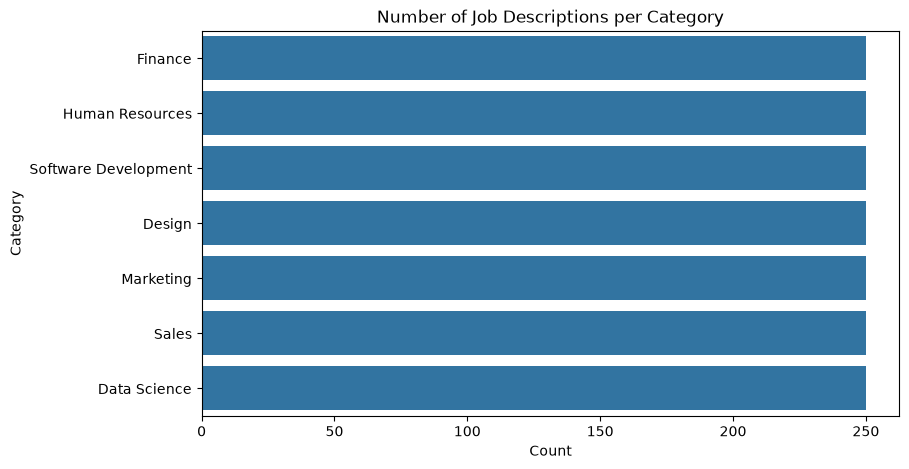

In [23]:
plt.figure(figsize=(9,5))

order = df["category"].value_counts().index

sns.countplot(
    y="category",
    data=df,
    order=order
)

plt.title("Number of Job Descriptions per Category")
plt.xlabel("Count")
plt.ylabel("Category")

plt.show()

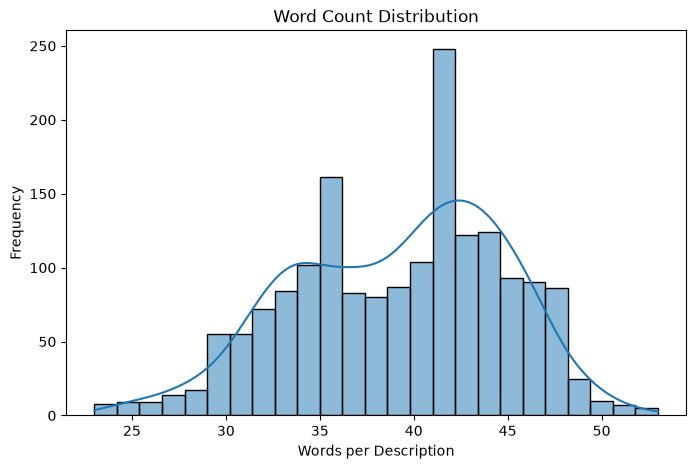

In [24]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["word_count"],
    bins=25,
    kde=True
)

plt.title("Word Count Distribution")
plt.xlabel("Words per Description")
plt.ylabel("Frequency")

plt.show()

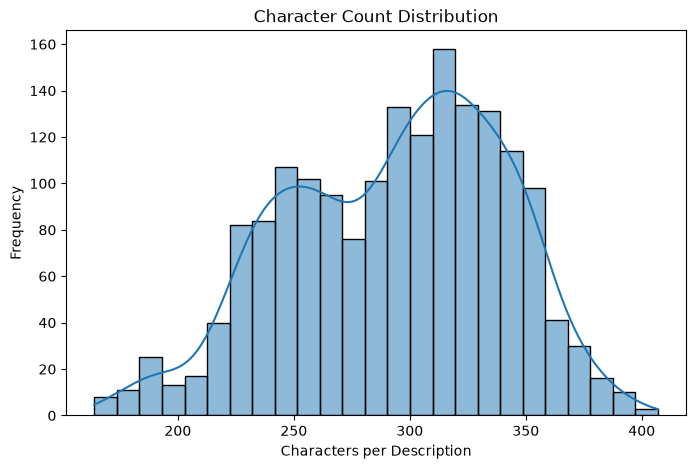

In [25]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["char_count"],
    bins=25,
    kde=True
)

plt.title("Character Count Distribution")
plt.xlabel("Characters per Description")
plt.ylabel("Frequency")

plt.show()

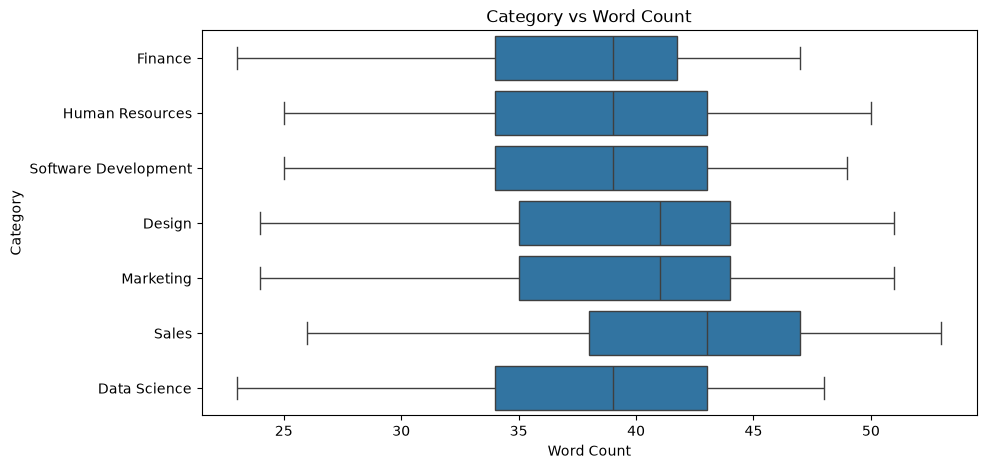

In [26]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x="word_count",
    y="category",
    data=df
)

plt.title("Category vs Word Count")

plt.xlabel("Word Count")
plt.ylabel("Category")

plt.show()

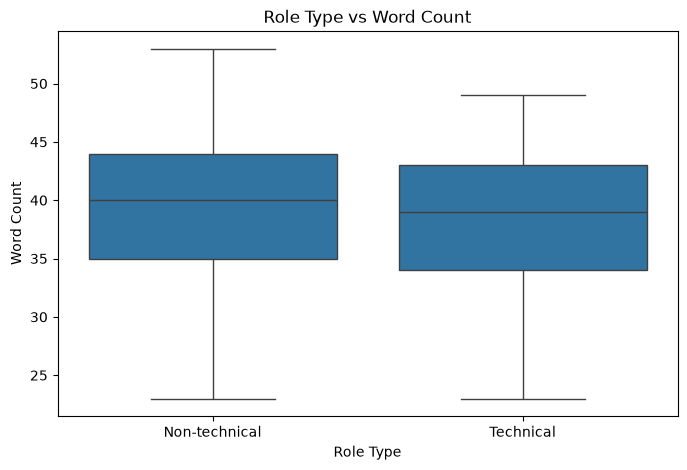

In [27]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="target",
    y="word_count",
    data=df
)

plt.xticks([0, 1], ["Non-technical", "Technical"])
plt.title("Role Type vs Word Count")

plt.xlabel("Role Type")
plt.ylabel("Word Count")

plt.show()

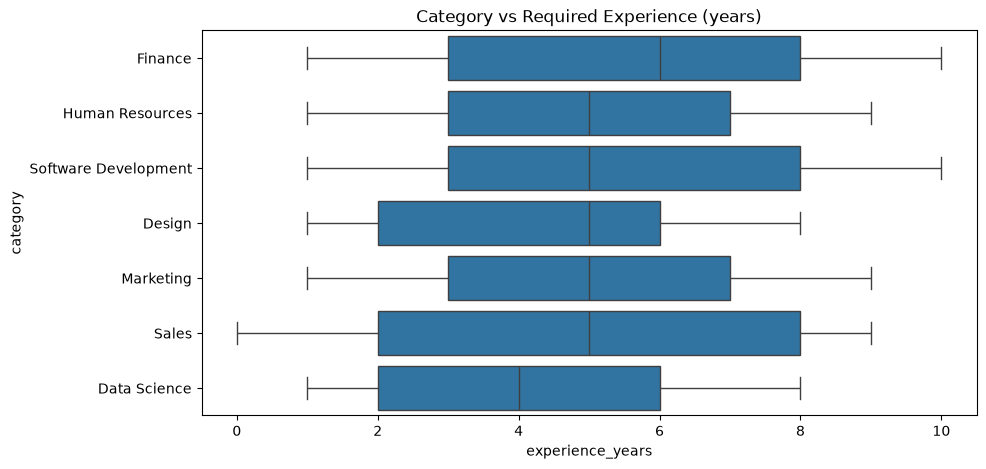

In [28]:
if "experience_years" in df.columns:
    plt.figure(figsize=(10,5))

    sns.boxplot(
        x="experience_years",
        y="category",
        data=df
    )

    plt.title("Category vs Required Experience (years)")

    plt.show()

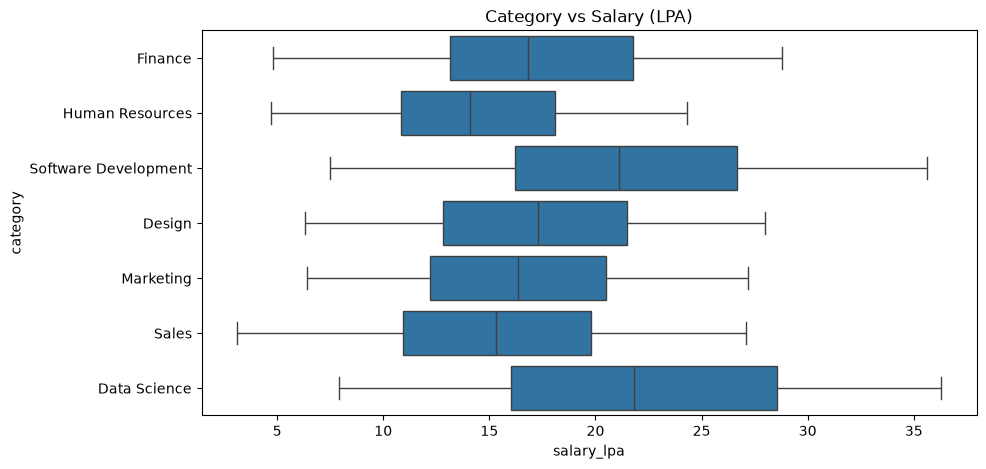

In [29]:
if "salary_lpa" in df.columns:
    plt.figure(figsize=(10,5))

    sns.boxplot(
        x="salary_lpa",
        y="category",
        data=df
    )

    plt.title("Category vs Salary (LPA)")

    plt.show()

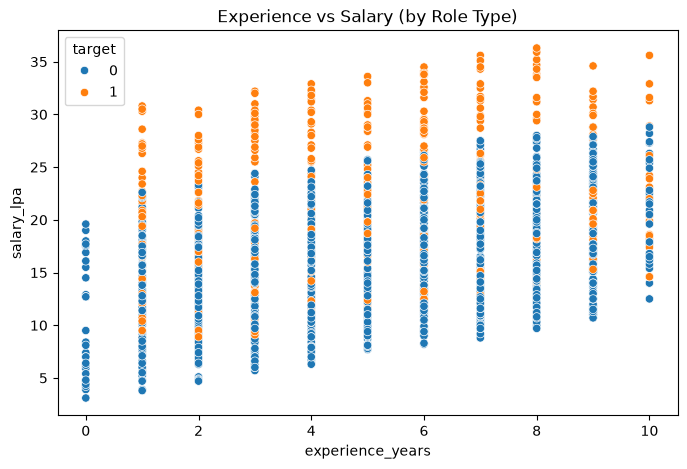

In [30]:
if "experience_years" in df.columns and "salary_lpa" in df.columns:
    plt.figure(figsize=(8,5))

    sns.scatterplot(
        x="experience_years",
        y="salary_lpa",
        hue="target",
        data=df
    )

    plt.title("Experience vs Salary (by Role Type)")

    plt.show()

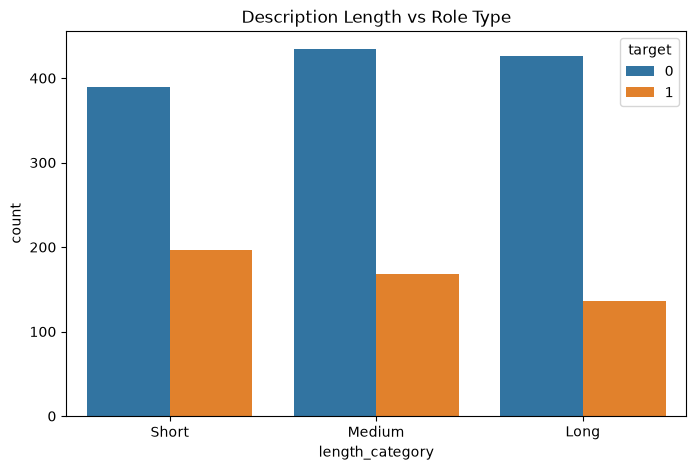

In [31]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="length_category",
    hue="target",
    data=df
)

plt.title("Description Length vs Role Type")

plt.show()

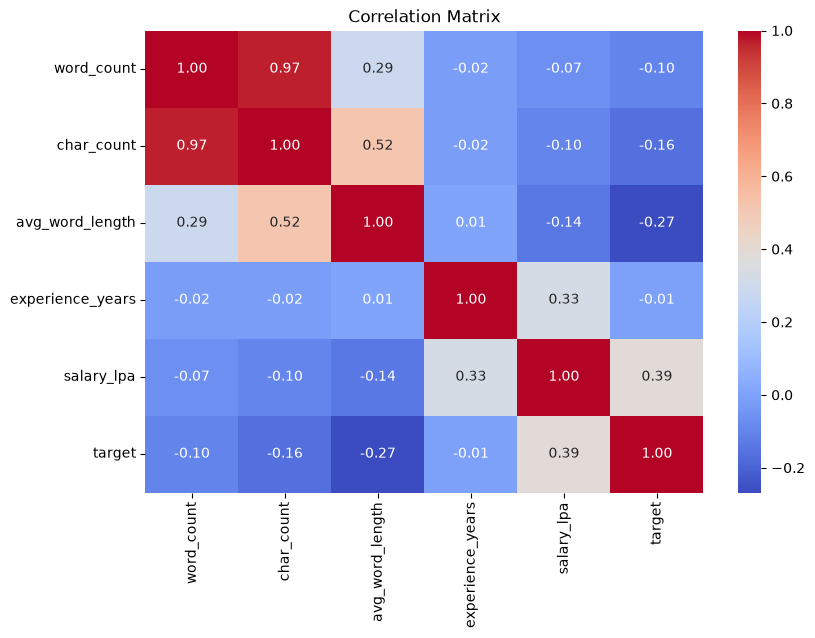

In [32]:
num_cols = [c for c in ["word_count", "char_count", "avg_word_length", "experience_years", "salary_lpa", "target"] if c in df.columns]

plt.figure(figsize=(9,6))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

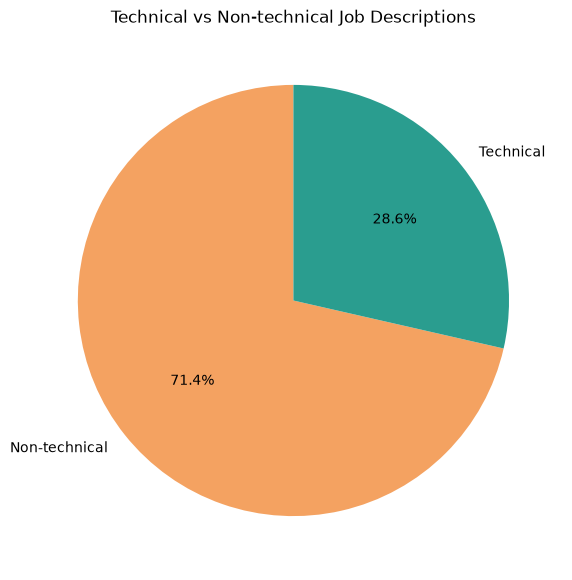

In [33]:
# Pie Chart - Technical vs Non-technical roles

counts = df["target"].value_counts().sort_index()

labels = ["Non-technical", "Technical"]

plt.figure(figsize=(7, 7))

plt.pie(
    counts,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#f4a261", "#2a9d8f"]
)

plt.title("Technical vs Non-technical Job Descriptions")

plt.show()

In [34]:
# Most common words per category (top 8, simple stop-word removal)
stop_words = set("""a an the and or of to in for with is are be as on at by this that you will we our your
years year experience required skills responsibilities strong good team work working looking hiring join
opportunity company position time full ability excellent plus essential environment positive attitude
player helpful familiarity communication growth opportunities collaborative deadlines meet problem solving
seeking experienced exciting""".split())

for cat in df["category"].unique():
    words = " ".join(df.loc[df["category"] == cat, "clean_description"]).split()
    words = [w for w in words if w not in stop_words and len(w) > 2]
    print(f"{cat:22s}", pd.Series(words).value_counts().head(8).index.tolist())

Finance                ['financial', 'analysis', 'manage', 'budgets', 'forecasts', 'modelling', 'accounting', 'budgeting']
Human Resources        ['employee', 'onboarding', 'performance', 'management', 'source', 'screen', 'candidates', 'payroll']
Software Development   ['backend', 'java', 'developer', 'write', 'clean', 'tested', 'code', 'maintain']
Design                 ['user', 'design', 'research', 'designer', 'systems', 'wireframing', 'intuitive', 'interfaces']
Marketing              ['campaigns', 'social', 'media', 'marketing', 'brand', 'seo', 'performance', 'coordinate']
Sales                  ['sales', 'client', 'business', 'presentation', 'maintain', 'target', 'achievement', 'b2b']
Data Science           ['learning', 'machine', 'data', 'design', 'experiments', 'analyze', 'create', 'large']


# Part 6 — Probability, Sampling and Bootstrap
Here `word_count` plays the role of the numeric variable, and `target` (technical = 1) is the binary variable.

In [35]:
# Probability of each category
print(df["category"].value_counts(normalize=True))

category
Finance                 0.142857
Human Resources         0.142857
Software Development    0.142857
Design                  0.142857
Marketing               0.142857
Sales                   0.142857
Data Science            0.142857
Name: proportion, dtype: float64


In [36]:
# Joint and conditional probability: category given length
print(pd.crosstab(df["length_category"], df["category"], normalize="index").round(3))

category         Data Science  Design  Finance  Human Resources  Marketing  \
length_category                                                              
Short                   0.169   0.137    0.152            0.162      0.133   
Medium                  0.135   0.131    0.184            0.136      0.145   
Long                    0.125   0.162    0.089            0.130      0.151   

category         Sales  Software Development  
length_category                               
Short            0.082                 0.166  
Medium           0.125                 0.145  
Long             0.226                 0.117  


In [37]:
print(df["target"].value_counts(normalize=True))

target
0    0.714286
1    0.285714
Name: proportion, dtype: float64


In [38]:
sample_means = []

for i in range(1000):

    sample = df["word_count"].sample(
        n=30,
        replace=False
    )

    sample_means.append(
        sample.mean()
    )

In [39]:
sample_means = pd.Series(sample_means)

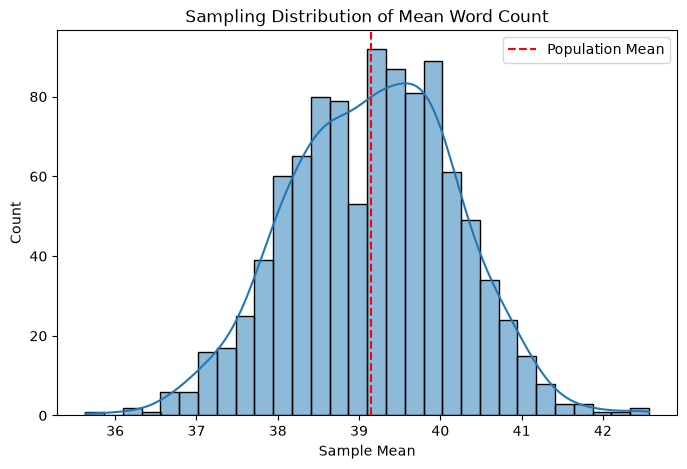

In [40]:
plt.figure(figsize=(8,5))

sns.histplot(
    sample_means,
    bins=30,
    kde=True
)

plt.axvline(
    df["word_count"].mean(),
    linestyle="--",
    color="red",
    label="Population Mean"
)

plt.title("Sampling Distribution of Mean Word Count")

plt.xlabel("Sample Mean")

plt.legend()

plt.show()

In [41]:
sample_sizes = [10, 30, 50, 100]
results = {}
for n in sample_sizes:
    means = []

    for i in range(1000):

        sample = df["word_count"].sample(
            n=n,
            replace=False
        )

        means.append(sample.mean())

    results[n] = means

In [42]:
for n in sample_sizes:

    print(
        "Sample size:",
        n,
        "Standard deviation of sample means:",
        np.std(results[n])
    )

Sample size: 10 Standard deviation of sample means: 1.7836286356750386
Sample size: 30 Standard deviation of sample means: 1.0095342358401391
Sample size: 50 Standard deviation of sample means: 0.8230635336351625
Sample size: 100 Standard deviation of sample means: 0.547823356931776


In [43]:
population_std = df["word_count"].std()

for n in sample_sizes:

    theoretical_se = population_std / np.sqrt(n)

    observed_se = np.std(results[n])

    print(
        f"\nSample Size: {n}"
    )

    print(
        "Theoretical SE:",
        theoretical_se
    )

    print(
        "Observed SE:",
        observed_se
    )


Sample Size: 10
Theoretical SE: 1.7776278190994128
Observed SE: 1.7836286356750386

Sample Size: 30
Theoretical SE: 1.0263138998760133
Observed SE: 1.0095342358401391

Sample Size: 50
Theoretical SE: 0.7949793284401971
Observed SE: 0.8230635336351625

Sample Size: 100
Theoretical SE: 0.5621352740431911
Observed SE: 0.547823356931776


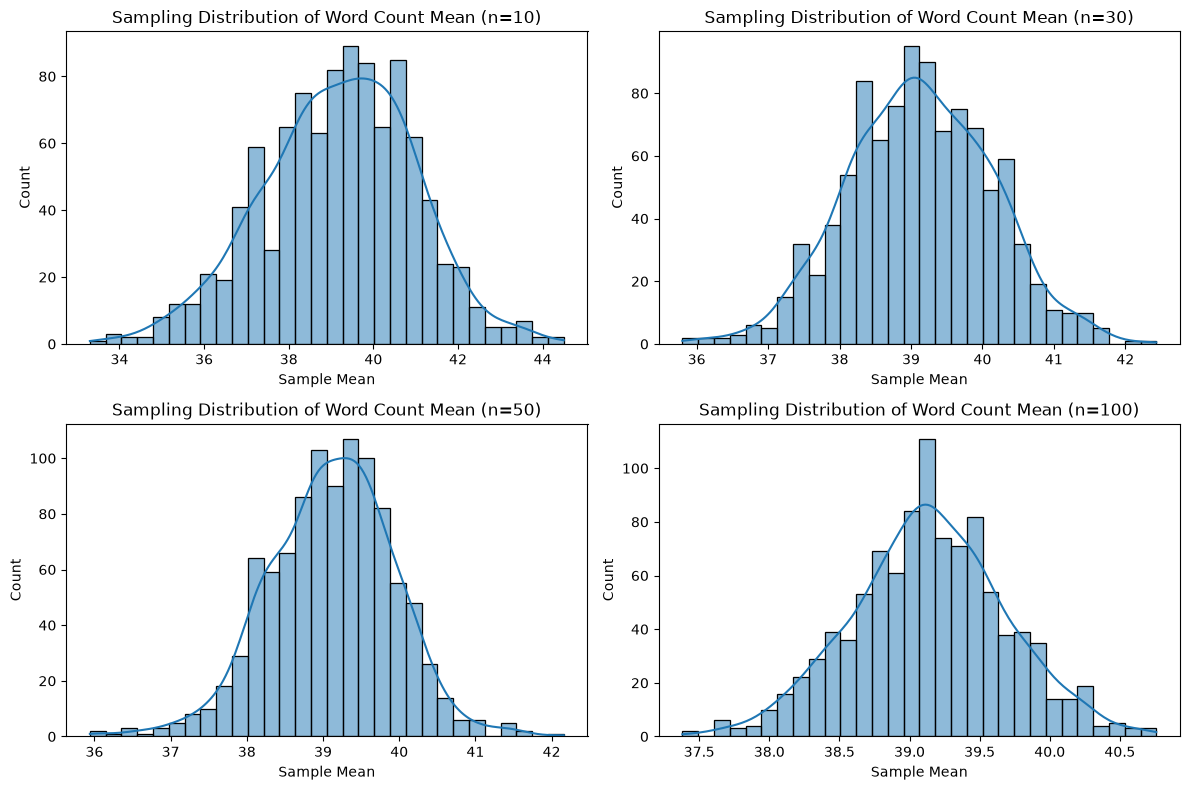

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, n in zip(axes.ravel(), sample_sizes):
    sns.histplot(results[n], bins=30, kde=True, ax=ax)
    ax.set_title(f"Sampling Distribution of Word Count Mean (n={n})")
    ax.set_xlabel("Sample Mean")

plt.tight_layout()
plt.show()

In [45]:
bootstrap_means = []

for i in range(10000):

    bootstrap_sample = df["word_count"].sample(
        n=len(df),
        replace=True
    )

    bootstrap_means.append(
        bootstrap_sample.mean()
    )

bootstrap_means = np.array(bootstrap_means)

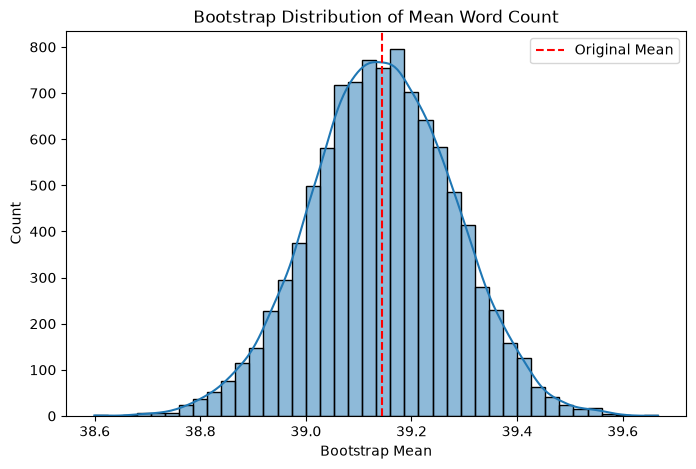

In [46]:
plt.figure(figsize=(8,5))

sns.histplot(
    bootstrap_means,
    bins=40,
    kde=True
)

plt.axvline(
    df["word_count"].mean(),
    linestyle="--",
    color="red",
    label="Original Mean"
)

plt.title("Bootstrap Distribution of Mean Word Count")

plt.xlabel("Bootstrap Mean")

plt.legend()

plt.show()

In [47]:
bootstrap_se = np.std(
    bootstrap_means,
    ddof=1
)

print(
    "Bootstrap Standard Error:",
    bootstrap_se
)

Bootstrap Standard Error: 0.13535343732475394


In [48]:
lower = np.percentile(
    bootstrap_means,
    2.5
)

upper = np.percentile(
    bootstrap_means,
    97.5
)

print("95% Bootstrap Confidence Interval (mean word count):")
print("Lower:", lower)
print("Upper:", upper)

95% Bootstrap Confidence Interval (mean word count):
Lower: 38.87542857142857
Upper: 39.40857142857143


In [49]:
bootstrap_proportions = []

for i in range(10000):

    sample = df["target"].sample(
        n=len(df),
        replace=True
    )

    bootstrap_proportions.append(
        sample.mean()
    )

bootstrap_proportions = np.array(
    bootstrap_proportions
)

In [50]:
prop_lower = np.percentile(
    bootstrap_proportions,
    2.5
)

prop_upper = np.percentile(
    bootstrap_proportions,
    97.5
)

print(f"Observed technical proportion: {df['target'].mean():.4f}")
print(f"95% Bootstrap CI: ({prop_lower:.4f}, {prop_upper:.4f})")

Observed technical proportion: 0.2857
95% Bootstrap CI: (0.2651, 0.3074)


In [51]:
tech_bootstrap_summary = {
    "Observed Technical Proportion":
        df["target"].mean(),

    "Bootstrap Mean":
        np.mean(bootstrap_proportions),

    "Bootstrap Standard Error":
        np.std(
            bootstrap_proportions,
            ddof=1
        ),

    "Lower 95% CI":
        np.percentile(
            bootstrap_proportions,
            2.5
        ),

    "Upper 95% CI":
        np.percentile(
            bootstrap_proportions,
            97.5
        )
}

tech_bootstrap_summary

{'Observed Technical Proportion': np.float64(0.2857142857142857),
 'Bootstrap Mean': np.float64(0.2858539428571429),
 'Bootstrap Standard Error': np.float64(0.010801036934342395),
 'Lower 95% CI': np.float64(0.2651428571428571),
 'Upper 95% CI': np.float64(0.30742857142857144)}

In [52]:
print("FINAL STATISTICAL SUMMARY")

print(f"Total observations           : {len(df)}")

print(f"Number of categories         : {df['category'].nunique()}")

print(f"Mean word count              : {df['word_count'].mean():.2f}")

print(f"Median word count            : {df['word_count'].median():.2f}")

print(f"Word count std deviation     : {df['word_count'].std():.2f}")

print(f"Mean character count         : {df['char_count'].mean():.2f}")

print(f"Technical proportion         : {df['target'].mean():.2%}")

print(f"Bootstrap mean word count    : {np.mean(bootstrap_means):.2f}")

print(f"Bootstrap SE                 : {np.std(bootstrap_means, ddof=1):.3f}")

print(
    f"95% Bootstrap CI for mean word count: "
    f"({np.percentile(bootstrap_means, 2.5):.2f}, "
    f"{np.percentile(bootstrap_means, 97.5):.2f})"
)

print(
    f"95% Bootstrap CI for technical proportion: "
    f"({prop_lower:.2%}, {prop_upper:.2%})"
)

FINAL STATISTICAL SUMMARY
Total observations           : 1750
Number of categories         : 7
Mean word count              : 39.14
Median word count            : 40.00
Word count std deviation     : 5.62
Mean character count         : 293.28
Technical proportion         : 28.57%
Bootstrap mean word count    : 39.15
Bootstrap SE                 : 0.135
95% Bootstrap CI for mean word count: (38.88, 39.41)
95% Bootstrap CI for technical proportion: (26.51%, 30.74%)


# Practical 5 — Confidence Intervals and Hypothesis Testing
This section analyzes the `word_count` of job descriptions and compares the mean with a stated reference value. Run after the dataset has been loaded, cleaned, and `df["target"]` created.

In [53]:
# Mean, standard deviation, standard error and 95% confidence interval for word count
words_series = df["word_count"].dropna()
n = len(words_series)
mean_wc = words_series.mean()
sd_wc = words_series.std(ddof=1)
se_wc = stats.sem(words_series)
confidence = 0.95
t_critical = stats.t.ppf((1 + confidence) / 2, df=n - 1)
margin_error = t_critical * se_wc
ci_lower, ci_upper = mean_wc - margin_error, mean_wc + margin_error

print("Sample size:", n)
print(f"Mean word count: {mean_wc:.2f}")
print(f"Standard deviation: {sd_wc:.2f}")
print(f"Standard error: {se_wc:.3f}")
print(f"T critical value (95% CI): {t_critical:.3f}")
print(f"Margin of error: {margin_error:.3f}")
print(f"95% confidence interval: ({ci_lower:.2f}, {ci_upper:.2f})")

Sample size: 1750
Mean word count: 39.14
Standard deviation: 5.62
Standard error: 0.134
T critical value (95% CI): 1.961
Margin of error: 0.264
95% confidence interval: (38.88, 39.41)


In [54]:
# Z critical value and confidence interval using a normal approximation
z_critical = stats.norm.ppf(0.975)
z_margin_error = z_critical * sd_wc / np.sqrt(n)
z_ci = (mean_wc - z_margin_error, mean_wc + z_margin_error)
print("Z critical value for 95% confidence:", round(z_critical, 3))
print("Z-based 95% confidence interval:", tuple(round(float(x), 2) for x in z_ci))
print("Note: population standard deviation is usually unknown, so the t interval is generally preferred.")

Z critical value for 95% confidence: 1.96
Z-based 95% confidence interval: (38.88, 39.41)
Note: population standard deviation is usually unknown, so the t interval is generally preferred.


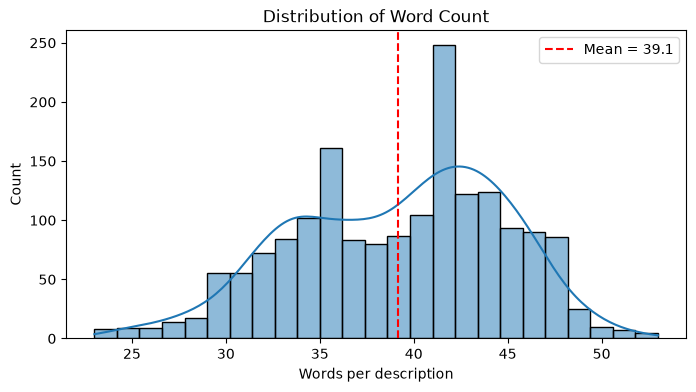

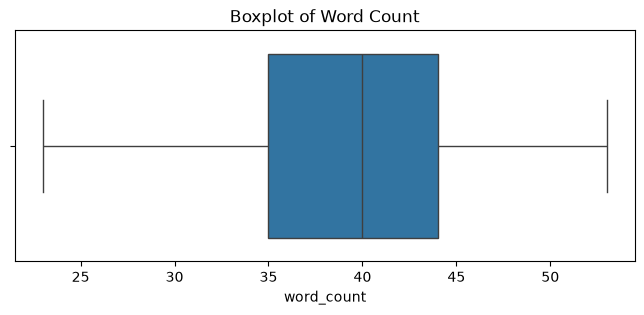

In [55]:
# Histogram and boxplot for word count
plt.figure(figsize=(8, 4))
sns.histplot(words_series, bins=25, kde=True)
plt.axvline(mean_wc, linestyle="--", color="red", label=f"Mean = {mean_wc:.1f}")
plt.title("Distribution of Word Count")
plt.xlabel("Words per description")
plt.legend()
plt.show()

plt.figure(figsize=(8, 3))
sns.boxplot(x=words_series)
plt.title("Boxplot of Word Count")
plt.show()

In [56]:
# One-sample t-test: test whether mean word count differs from 50 words
# H0: population mean word count = 50; H1: population mean word count != 50
reference_mean = 50
t_stat, p_value = stats.ttest_1samp(words_series, popmean=reference_mean)
alpha = 0.05
print("t-statistic:", round(t_stat, 4))
print("p-value:", round(p_value, 6))
print("Significance level:", alpha)
if p_value < alpha:
    print(f"Decision: Reject H0. The mean word count is statistically different from {reference_mean}.")
else:
    print(f"Decision: Fail to reject H0. There is not enough evidence that the mean word count differs from {reference_mean}.")

t-statistic: -80.7882
p-value: 0.0
Significance level: 0.05
Decision: Reject H0. The mean word count is statistically different from 50.


In [57]:
# One-sample Z-test (large-sample approximation using sample SD)
# H0: mean word count = 50; two-sided test
z_stat = (mean_wc - reference_mean) / (sd_wc / np.sqrt(n))
z_p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))
print("Z statistic:", round(z_stat, 4))
print("Z-test p-value:", round(z_p_value, 6))
print("Decision:", "Reject H0" if z_p_value < alpha else "Fail to reject H0")
print("Teaching note: a true one-sample Z-test assumes the population SD is known; this example uses sample SD as an approximation.")

Z statistic: -80.7882
Z-test p-value: 0.0
Decision: Reject H0
Teaching note: a true one-sample Z-test assumes the population SD is known; this example uses sample SD as an approximation.


# Practical 6 — Independent and Paired T-Tests
The independent test compares two separate groups in the real dataset: technical and non-technical job descriptions. The paired test requires before-and-after measurements from the same units; this dataset has no such pair, so the second example uses clearly labeled demonstration data.

Technical group mean word count: 38.25
Non-technical group mean word count: 39.5
Welch t-statistic: -4.257
p-value: 2.3e-05
Decision: Reject H0: evidence of a difference in mean word count


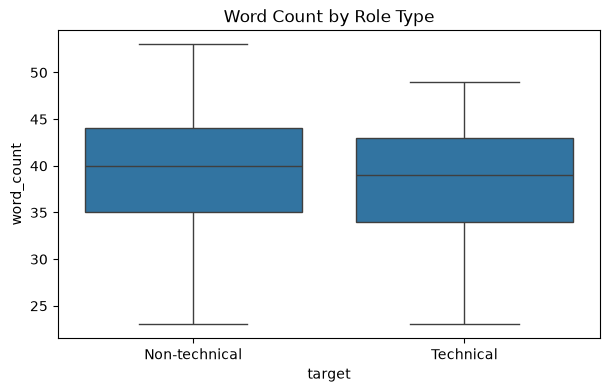

In [58]:
# Independent two-sample t-test: word count of technical vs non-technical descriptions
# H0: the two groups have equal population mean word count
# H1: the population mean word count differs
group_no = df.loc[df["target"] == 0, "word_count"].dropna()
group_yes = df.loc[df["target"] == 1, "word_count"].dropna()
t_ind, p_ind = stats.ttest_ind(group_yes, group_no, equal_var=False)  # Welch's t-test
print("Technical group mean word count:", round(group_yes.mean(), 2))
print("Non-technical group mean word count:", round(group_no.mean(), 2))
print("Welch t-statistic:", round(t_ind, 4))
print("p-value:", round(p_ind, 6))
print("Decision:", "Reject H0: evidence of a difference in mean word count" if p_ind < 0.05 else "Fail to reject H0: insufficient evidence of a difference")
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="target", y="word_count")
plt.xticks([0, 1], ["Non-technical", "Technical"])
plt.title("Word Count by Role Type")
plt.show()

In [59]:
# Second independent t-test: salary of technical vs non-technical roles (if salary exists)
if "salary_lpa" in df.columns:
    sal_yes = df.loc[df["target"] == 1, "salary_lpa"]
    sal_no = df.loc[df["target"] == 0, "salary_lpa"]
    t_sal, p_sal = stats.ttest_ind(sal_yes, sal_no, equal_var=False)
    print("Technical mean salary (LPA):", round(sal_yes.mean(), 2))
    print("Non-technical mean salary (LPA):", round(sal_no.mean(), 2))
    print("Welch t-statistic:", round(t_sal, 4))
    print("p-value:", round(p_sal, 6))
    print("Decision:", "Reject H0: evidence of a difference in mean salary" if p_sal < 0.05 else "Fail to reject H0: insufficient evidence of a difference")
else:
    print("No salary column in this dataset; skipping.")

Technical mean salary (LPA): 21.65
Non-technical mean salary (LPA): 16.05
Welch t-statistic: 15.9556
p-value: 0.0
Decision: Reject H0: evidence of a difference in mean salary


In [60]:
# Chi-square test of independence: is description length related to role type?
contingency = pd.crosstab(df["length_category"], df["target"])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
print(contingency)
print("\nChi-square:", round(chi2, 4), "| dof:", dof, "| p-value:", round(p_chi, 6))
print("Decision:", "Reject H0: length category and role type are related" if p_chi < 0.05 else "Fail to reject H0: no evidence of a relationship")

target             0    1
length_category          
Short            390  196
Medium           434  168
Long             426  136

Chi-square: 12.2202 | dof: 2 | p-value: 0.00222
Decision: Reject H0: length category and role type are related


In [61]:
# Paired t-test demonstration (illustrative data only; not from the job dataset)
# Example: screening time (minutes) for the same 8 recruiters before and after using an automatic classifier.
before = np.array([14, 18, 12, 21, 16, 19, 15, 17])
after  = np.array([9, 12, 10, 14, 11, 13, 10, 12])
t_paired, p_paired = stats.ttest_rel(before, after)
print("Before mean:", round(before.mean(), 2))
print("After mean:", round(after.mean(), 2))
print("Paired t-statistic:", round(t_paired, 4))
print("p-value:", round(p_paired, 6))
print("Decision:", "Reject H0: evidence of a before-after difference" if p_paired < 0.05 else "Fail to reject H0: insufficient evidence of a before-after difference")
print("Important: replace these illustrative values with genuine matched measurements for a real study.")

Before mean: 16.5
After mean: 11.38
Paired t-statistic: 9.944
p-value: 2.2e-05
Decision: Reject H0: evidence of a before-after difference
Important: replace these illustrative values with genuine matched measurements for a real study.


# Practical 7 — Text Classification (TF-IDF + Machine Learning Models)
The job description text is converted to numbers with **TF-IDF**, and several classifiers are trained to predict the job `category`. Models are compared using accuracy, precision, recall and F1-score.

In [62]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
import joblib

X_text = df["clean_description"]
y = df["category"]

X_train_t, X_test_t, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english",
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_t)   # fit only on training data (no leakage)
X_test_tfidf = tfidf.transform(X_test_t)

print("Training rows:", X_train_tfidf.shape[0], "| Test rows:", X_test_tfidf.shape[0])
print("TF-IDF features:", X_train_tfidf.shape[1])

Training rows: 1400 | Test rows: 350
TF-IDF features: 2873


In [63]:
# Train and compare five classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(max_depth=20, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
}

results_list = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    results_list.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1": f1_score(y_test, pred, average="weighted", zero_division=0)
    })
    fitted_models[name] = model

results_df = pd.DataFrame(results_list).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df)

best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
print("Best model by weighted F1:", best_name)

,Model,Accuracy,Precision,Recall,F1
0,Linear SVM,0.980000,0.980280,0.980000,0.980056
1,Logistic Regression,0.960000,0.961088,0.960000,0.960069
2,Naive Bayes,0.954286,0.955155,0.954286,0.954386
3,Random Forest,0.942857,0.943764,0.942857,0.942921
4,Decision Tree,0.745714,0.756572,0.745714,0.746182


Best model by weighted F1: Linear SVM


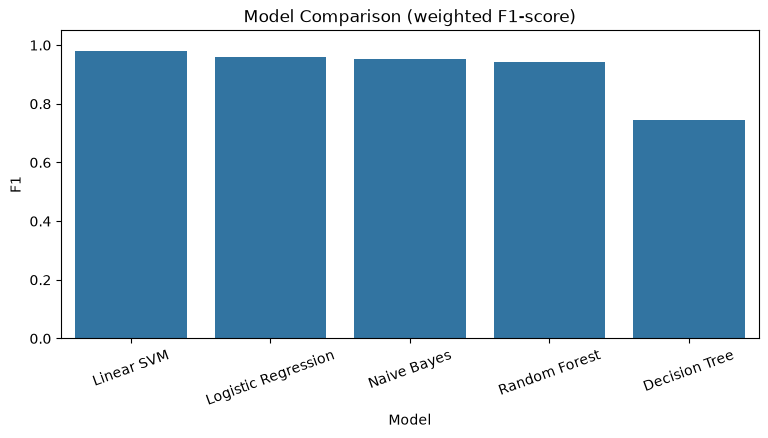

In [64]:
plt.figure(figsize=(9, 4))
sns.barplot(data=results_df, x="Model", y="F1")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.title("Model Comparison (weighted F1-score)")
plt.show()

                      precision    recall  f1-score   support

        Data Science       0.96      0.98      0.97        50
              Design       0.96      0.96      0.96        50
             Finance       1.00      0.98      0.99        50
     Human Resources       0.96      0.98      0.97        50
           Marketing       1.00      0.98      0.99        50
               Sales       1.00      0.98      0.99        50
Software Development       0.98      1.00      0.99        50

            accuracy                           0.98       350
           macro avg       0.98      0.98      0.98       350
        weighted avg       0.98      0.98      0.98       350



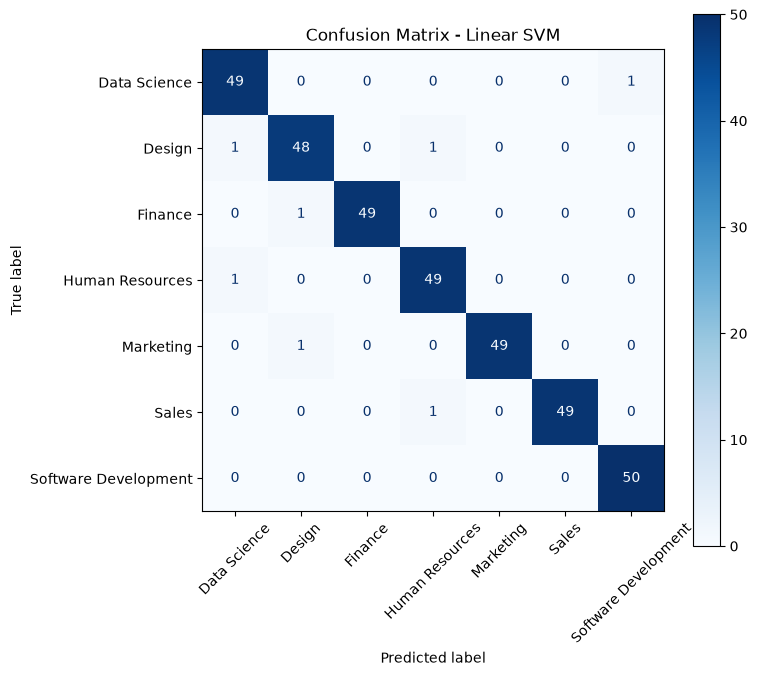

In [65]:
# Classification report and confusion matrix for the best model
best_pred = best_model.predict(X_test_tfidf)

print(classification_report(y_test, best_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, xticks_rotation=45, cmap="Blues", ax=ax
)
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

In [66]:
# 5-fold stratified cross-validation of the best model (full pipeline, so TF-IDF is refit in each fold)
pipe_cv = make_pipeline(
    TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words="english", sublinear_tf=True),
    type(best_model)(**best_model.get_params())
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe_cv, X_text, y, cv=cv, scoring="accuracy")
print("CV accuracy per fold:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

CV accuracy per fold: [0.98   0.9857 0.9771 0.9686 0.9743]
Mean CV accuracy: 0.9771 (+/- 0.0057)


In [67]:
# Most important words per category (Logistic Regression coefficients)
log_reg = fitted_models["Logistic Regression"]
feature_names = np.array(tfidf.get_feature_names_out())

for i, cls in enumerate(log_reg.classes_):
    top = np.argsort(log_reg.coef_[i])[-8:][::-1]
    print(f"{cls:22s}", feature_names[top].tolist())

Data Science           ['learning', 'machine learning', 'machine', 'data', 'data analyst', 'sql', 'design experiments', 'experiments']
Design                 ['designer', 'designer years', 'user', 'design', 'user research', 'wireframing', 'typography', 'collaborate']
Finance                ['financial', 'analysis', 'accounting', 'budgeting', 'taxation', 'reconcile', 'accounts', 'reconcile accounts']
Human Resources        ['employee', 'hr', 'skills communication', 'onboarding', 'interviews', 'conduct interviews', 'performance management', 'management']
Marketing              ['seo', 'campaigns', 'brand', 'social media', 'media', 'social', 'marketing', 'branding']
Sales                  ['sales', 'client', 'presentation', 'presentation skills', 'business', 'skills lead', 'deals customers', 'customers']
Software Development   ['developer', 'backend', 'developer years', 'java', 'git', 'docker', 'react', 'skills git']


In [68]:
# Save selected model and the TF-IDF vectorizer
joblib.dump(best_model, "best_job_classifier.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("Saved: best_job_classifier.pkl and tfidf_vectorizer.pkl")

# Example: load the files and classify a new job description
loaded_model = joblib.load("best_job_classifier.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

sample_jd = (
    "We are hiring a candidate with 3+ years of experience. Responsibilities: build predictive models, "
    "analyze large datasets. Required skills: python, machine learning, sql, statistics."
)

sample_vec = loaded_tfidf.transform([clean_text(sample_jd)])
print("Predicted category:", loaded_model.predict(sample_vec)[0])

Saved: best_job_classifier.pkl and tfidf_vectorizer.pkl
Predicted category: Data Science


# Practical 8 — Classification Using Text + Numeric Features
This section adds numeric features (`word_count`, `char_count`, `avg_word_length`, and `experience_years` / `salary_lpa` when available) to the TF-IDF text features and checks whether they improve the classifier.

In [69]:
from scipy.sparse import hstack, csr_matrix

numeric_features = [c for c in ["word_count", "char_count", "avg_word_length", "experience_years", "salary_lpa"] if c in df.columns]
print("Numeric features used:", numeric_features)

train_idx = X_train_t.index
test_idx = X_test_t.index

num_scaler = StandardScaler()
X_train_num = num_scaler.fit_transform(df.loc[train_idx, numeric_features])
X_test_num = num_scaler.transform(df.loc[test_idx, numeric_features])

X_train_comb = hstack([X_train_tfidf, csr_matrix(X_train_num)]).tocsr()
X_test_comb = hstack([X_test_tfidf, csr_matrix(X_test_num)]).tocsr()

print("Combined feature matrix:", X_train_comb.shape)

Numeric features used: ['word_count', 'char_count', 'avg_word_length', 'experience_years', 'salary_lpa']
Combined feature matrix: (1400, 2878)


,Model,Features,Accuracy,F1
0,Logistic Regression,Text only,0.960000,0.960069
1,Logistic Regression,Text + numeric,0.965714,0.965802
2,Random Forest,Text only,0.942857,0.942921
3,Random Forest,Text + numeric,0.937143,0.937316


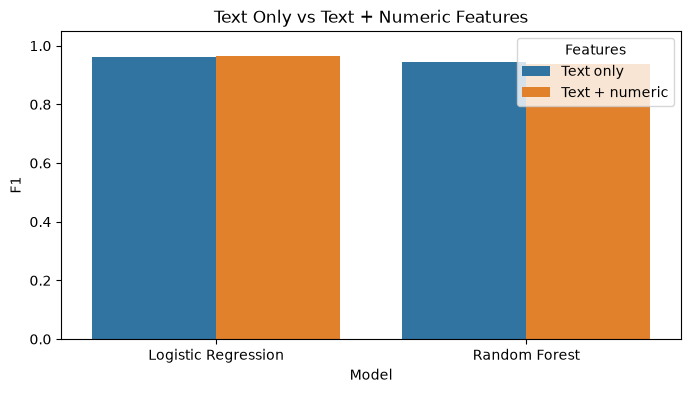

In [70]:
# Compare text-only vs text + numeric using Logistic Regression and Random Forest
compare = []
for name, model_cls in {
    "Logistic Regression": lambda: LogisticRegression(max_iter=2000),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
}.items():
    for label, (Xtr, Xte) in {"Text only": (X_train_tfidf, X_test_tfidf),
                              "Text + numeric": (X_train_comb, X_test_comb)}.items():
        m = model_cls()
        m.fit(Xtr, y_train)
        p = m.predict(Xte)
        compare.append({
            "Model": name, "Features": label,
            "Accuracy": accuracy_score(y_test, p),
            "F1": f1_score(y_test, p, average="weighted")
        })

compare_df = pd.DataFrame(compare)
display(compare_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=compare_df, x="Model", y="F1", hue="Features")
plt.ylim(0, 1.05)
plt.title("Text Only vs Text + Numeric Features")
plt.show()

In [71]:
# Binary version: technical vs non-technical (uses the helper column `target`)
y_bin = df.loc[X_text.index, "target"]
ytr_b, yte_b = y_bin.loc[train_idx], y_bin.loc[test_idx]

bin_model = LogisticRegression(max_iter=1000)
bin_model.fit(X_train_tfidf, ytr_b)
bin_pred = bin_model.predict(X_test_tfidf)

print("Binary accuracy:", round(accuracy_score(yte_b, bin_pred), 4))
print(classification_report(yte_b, bin_pred, target_names=["Non-technical", "Technical"], zero_division=0))

Binary accuracy: 0.9829
               precision    recall  f1-score   support

Non-technical       0.98      0.99      0.99       250
    Technical       0.98      0.96      0.97       100

     accuracy                           0.98       350
    macro avg       0.98      0.98      0.98       350
 weighted avg       0.98      0.98      0.98       350



# Streamlit GUI
The cell below writes the Streamlit app to `app.py`. It loads the saved model (`best_job_classifier.pkl`) and TF-IDF vectorizer (`tfidf_vectorizer.pkl`) created earlier in this notebook, so run the "Save selected model" cell first.

In [72]:
%%writefile app.py
import re
import joblib
import streamlit as st

st.set_page_config(page_title="Job Description Classifier", page_icon="💼")


@st.cache_resource
def load_artifacts():
    """Load the saved model and TF-IDF vectorizer once."""
    model = joblib.load("best_job_classifier.pkl")
    tfidf = joblib.load("tfidf_vectorizer.pkl")
    return model, tfidf


def clean_text(text):
    """Same cleaning function that was used during training."""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # remove urls
    text = re.sub(r"[^a-z0-9+#\s]", " ", text)      # keep letters, digits, + and #
    text = re.sub(r"\s+", " ", text).strip()
    return text


model, tfidf = load_artifacts()

st.title("Job Description Classifier")
st.write("Educational demo: predicts the job category from the description text.")

job_text = st.text_area("Paste a job description", height=220)

if st.button("Predict", type="primary"):
    if not job_text.strip():
        st.warning("Please paste a job description first.")
    else:
        vec = tfidf.transform([clean_text(job_text)])
        label = model.predict(vec)[0]
        st.success(f"Predicted job category: {label}")

Overwriting app.py


In [73]:
# Install Streamlit (run once)
%pip install streamlit -q

# ---- Option 1: run locally (Jupyter / VS Code) ----
# Open a terminal in this folder and run:
#     streamlit run app.py
# The app opens in the browser at http://localhost:8501

# ---- Option 2: run in Google Colab ----
# Uncomment the lines below, then open the localtunnel URL that is printed.
# !npm install localtunnel -q
# !streamlit run app.py &>/content/logs.txt &
# import urllib
# print("Tunnel password (public IP):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode("utf8").strip())
# !npx localtunnel --port 8501

Note: you may need to restart the kernel to use updated packages.


# Conclusion
- Job descriptions were collected/generated, cleaned, and converted to numeric features with TF-IDF.
- Statistical analysis (sampling distribution, bootstrap, confidence intervals, t-tests, chi-square) described the data.
- Multiple classifiers were compared; the best model was selected using weighted F1-score, cross-validated and saved with `joblib`.
- If the synthetic dataset was used, scores will be very high because the generated text is easy to separate; with a real job-postings dataset, expect lower and more realistic scores.